# 06 · Does it work? The validation suite

> **What and why**
>
> - Nobody knows the true number of fires, so we test the record against a witness.
> - MODIS flew the whole time with the same camera. Across 2012 the harmonized record must change by the same factor as MODIS.
> - Terra flew alone before July 2002 and on after it. Across 2002 the record must change by the same factor as Terra.
> - To know how big a step is normal, we run the same test at dates when nothing changed (placebo seams).
> - We also run change point tests, compare the model with VIIRS in the years VIIRS flew, and check that the worst months stay the worst.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
import json
from IPython.display import Image
from fireharmony import validate as V
MODELS = REPO / 'models'
val = json.loads((MODELS / 'validation.json').read_text())
bridge = json.loads((MODELS / 'terra_only_bridge.json').read_text())
world = pd.read_parquet(C.work('models', 'world_monthly.parquet'))
HZ = C.work('harmonized_l5', 'year=*', 'data.parquet')
FLEET = C.work('gold', 'fleet_month.parquet')

## 1. The seam tests

The seam ratio is the mean of the years after a seam divided by the mean of the years before it. We use one year each side for 2002 (the archive starts in November 2000) and three years for 2012. A good record changes by the same factor as its witness.

Terra missed some days (half of June 2001, a week of March 2002), so we correct each Terra month for its missing days (`terra_cc`). The raw Terra count (`terra_raw`) would make the year before the seam look too small.

In [2]:
pd.DataFrame(val['seam_ratios']).set_index('series')

,seam_2002_07,seam_2012_01
series,,
terra_cc,1.036,0.995
terra_raw,1.060,0.995
modis_scale,0.963,0.973
harmonized,1.045,0.989
naive_join,0.963,7.870
model_terra_aqua,NaN,0.990
model_terra_only,1.059,NaN


## 2. Steps against the witness

Fire really changes from year to year, and the witness sees those changes too. So we divide each record by its witness, month by month. If the record is consistent, this ratio stays the same across the seam, and any step left belongs to the record itself. The windows hold the same calendar months on both sides (July to June for 2002, January to December for 2012).

In [3]:
rows = []
for seam, cols in val['per_witness'].items():
    for col, w in cols.items():
        for win, r in w.items():
            rows.append({'seam': seam.replace('_', ' '), 'series': col, 'window after the seam': win, 'step (%)': round(r['step_pct'], 2)})
# the same test without the Terra only bridge (section 4): the raw Terra only model before July 2002
raw = world.assign(unbridged=np.where(world.yr * 100 + world.mo < 200207, world.model_terra_only, world.harmonized))
rows.append({'seam': '2002 terra witness', 'series': 'harmonized without the bridge', 'window after the seam': '1y',
             'step (%)': round(V.per_witness(raw, 'unbridged', 'terra_cc', '2002-07-01', '2001-07-01', 1)['step_pct'], 2)})
pd.DataFrame(rows)

,seam,series,window after the seam,step (%)
0,2002 terra witness,harmonized,1y,0.85
1,2002 terra witness,modis_scale,1y,-7.05
2,2012 modis witness,harmonized,1y,0.55
3,2012 modis witness,harmonized,3y,1.65
4,2012 modis witness,naive_join,1y,699.19
5,2012 modis witness,naive_join,3y,709.24
6,2002 terra witness,harmonized without the bridge,1y,3.63


## 3. How big is a normal step? Placebo seams

The record and its witness never see exactly the same fires, so their ratio moves a little every year, seam or not. To see how much, we run the same one year test at dates when no satellite joined or left: every July from 2003 to 2010 against Terra, and every January from 2004 to 2011 against MODIS. A real seam problem would stand far outside the spread of these placebo steps.

In [4]:
pl = val['placebo_seams']
pd.DataFrame([{'seam': k.replace('_', ' '), 'real step (%)': d['real_step'], 'placebo mean (%)': d['mean'], 'placebo sd (%)': d['sd'],
               'largest placebo step (%)': d['max_abs'], 'z of the real step': d['z']} for k, d in pl.items()]).set_index('seam').round(2)

,real step (%),placebo mean (%),placebo sd (%),largest placebo step (%),z of the real step
seam,,,,,
2002 terra witness,0.85,1.2,4.97,8.40,-0.07
2012 modis witness,0.55,0.1,1.22,1.92,0.37


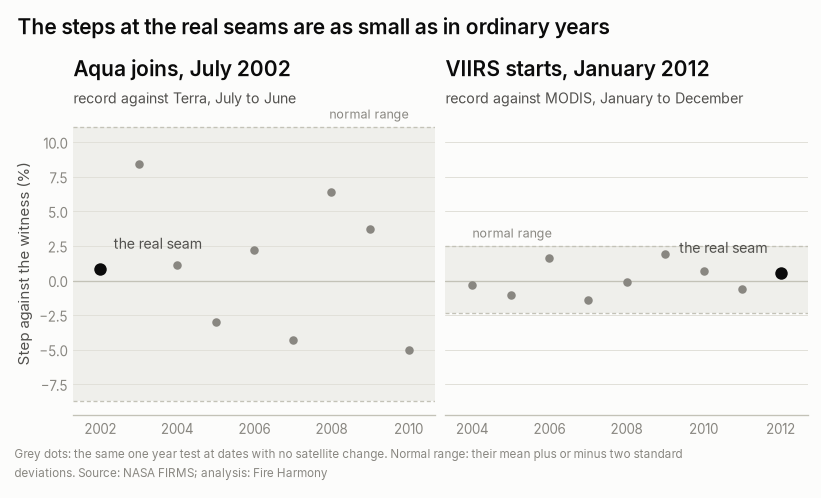

In [5]:
fig, axes = plt.subplots(1, 2, figsize=fh.SIZE['full'], sharey=True)
for ax, (key, d), real_year, name in zip(axes, pl.items(), (2002, 2012),
                                         ('Aqua joins, July 2002', 'VIIRS starts, January 2012')):
    yrs = np.array([int(y) for y in d['steps']]); st = np.array(list(d['steps'].values()))
    lo, hi = d['mean'] - 2 * d['sd'], d['mean'] + 2 * d['sd']
    ax.axhspan(lo, hi, color=fh.GRID, alpha=0.45, lw=0)
    for v in (lo, hi):
        ax.axhline(v, color=fh.BASELINE, lw=0.8, ls=(0, (3, 2)))
    ax.axhline(0, color=fh.BASELINE, lw=0.8)
    ax.scatter(yrs, st, s=26, color=fh.MUTED, zorder=3)
    ax.scatter([real_year], [d['real_step']], s=56, color=fh.INK, zorder=4)
    left = real_year > yrs.max()                       # 2012: the placebo years come before the seam
    ax.annotate('the real seam', (real_year, d['real_step']), xytext=(-8 if left else 8, 10), textcoords='offset points',
                ha='right' if left else 'left', va='bottom', fontsize=8.5, color=fh.INK_2)
    ax.annotate('normal range', (yrs.min() if left else yrs.max(), hi), xytext=(0, 3), textcoords='offset points',
                ha='left' if left else 'right', va='bottom', fontsize=7.5, color=fh.MUTED)
    fh.clean(ax)
    span = np.r_[yrs, real_year]
    ax.set_xticks(np.arange(span.min(), span.max() + 1, 2))
    ax.set_xlim(span.min() - 0.7, span.max() + 0.7)
    fh.title(ax, name, 'record against Terra, July to June' if key.startswith('2002') else 'record against MODIS, January to December')
axes[0].set_ylabel('Step against the witness (%)')
fig.suptitle('The steps at the real seams are as small as in ordinary years', x=0.01, ha='left', fontsize=12.5, fontweight='semibold')
fh.source(fig, 'Grey dots: the same one year test at dates with no satellite change. Normal range: their mean plus or minus two standard deviations. '
               'Source: NASA FIRMS; analysis: Fire Harmony')
fig.get_layout_engine().set(rect=(0, 0.035, 1, 0.95))
fh.save(fig, FIG / 'fig13_placebo_seams')

## 3b. A witness that VIIRS cannot touch: burned area

ESA's Fire_cci burned area (MRBA60H) is made from MODIS 250 m images, the same way for 2003 to 2018. The switch to VIIRS in our record does not change it. So the number of hotspots per km2 burned should not step at 2012. We run the same step and placebo tests against it (its Sentinel 3 continuation from 2019 is left out, because it would be a seam of its own).

In [6]:
bw = val['burned_area_witness']
pd.DataFrame([{'window': k, 'harmonized step (%)': d['step_pct']['harmonized'], 'MODIS step (%)': d['step_pct']['modis_scale'],
               'naive join step (%)': d['step_pct']['naive_join'], 'placebo sd (%)': d['placebo_sd'], 'z of the harmonized step': d['z']}
              for k, d in bw.items() if k in ('1y', '3y')]).set_index('window').round(2)

,harmonized step (%),MODIS step (%),naive join step (%),placebo sd (%),z of the harmonized step
window,,,,,
1y,3.19,2.62,720.14,4.21,0.94
3y,3.27,1.59,722.11,3.58,0.77


In [7]:
hpk = pd.Series(bw['hotspots_per_km2_burned']).rename('harmonized hotspots per km2 burned')
print('yearly correlation with burned area:', {k: round(v, 3) for k, v in bw['yearly_correlation'].items()})
hpk.round(2).to_frame().T

yearly correlation with burned area: {'harmonized': 0.86, 'modis_scale': 0.895}


,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
harmonized hotspots per km2 burned,3.17,2.91,2.99,2.93,2.93,2.88,2.95,2.96,2.81,2.9,3.09,3.03,3.14,3.13,2.9,2.91


## 4. The two models where both ran: the Terra only bridge

Before July 2002 only Terra flew, so the record there comes from the Terra only model. After it the Terra + Aqua model takes over. Both models ran in many later years, so we can compare them. In the training years (2013 to 2019) they agree within about 1.5% for the world. In the first years after the seam the Terra only model reads lower, and some regions differ a lot more. The gap also drifts slowly over the years. So we bridge the Terra only model to the Terra + Aqua model, region by region (level 1 hexagons), with ratios learned in the three years after July 2002. This is the same idea as the bridges that put Suomi NPP and NOAA-21 on the NOAA-20 scale.

In [8]:
both = world[world.model_terra_only.notna() & world.model_terra_aqua.notna() & (world.model_terra_only > 0)]
by_year = both.groupby('yr').apply(lambda g: g.model_terra_aqua.sum() / g.model_terra_only.sum(), include_groups=False).rename('world')
cont = con.execute(f'''
  WITH j AS (SELECT s.continent, CASE WHEN h.yr * 100 + h.mo BETWEEN 200207 AND 200506 THEN '2002 to 2005'
                                      WHEN h.yr * 100 + h.mo BETWEEN 200507 AND 200812 THEN '2005 to 2008'
                                      WHEN h.yr BETWEEN 2013 AND 2019 THEN '2013 to 2019' END AS period, h.pred_ta, h.pred_t
             FROM read_parquet('{HZ}') h JOIN '{FE.out_path("cell_static_l5")}' s USING (cell)
             WHERE h.pred_ta IS NOT NULL AND h.pred_t IS NOT NULL)
  SELECT continent, period, sum(pred_ta) / sum(pred_t) AS ratio, sum(pred_t) AS t FROM j
  WHERE period IS NOT NULL GROUP BY 1, 2''').df()
cont = cont[cont.groupby('continent').t.transform('min') > 1e6].pivot(index='continent', columns='period', values='ratio')
k = pd.Series(bridge['regions'])
print('Terra + Aqua model / Terra only model, world, by year:'); print(by_year.round(3).to_frame().T.to_string())
print(f"\nBridge: world ratio {bridge['k_global']:.3f}; regions: middle 90% from {k.quantile(0.05):.2f} to {k.quantile(0.95):.2f}")
cont.round(3)

Terra + Aqua model / Terra only model, world, by year:
yr      2002  2003   2004   2005   2006   2007  2008   2012  2013   2014   2015   2016   2017   2018   2019
world  1.016  1.04  1.043  1.034  1.019  1.024  1.03  1.015  1.01  1.003  1.007  0.999  0.992  0.987  0.991

Bridge: world ratio 1.033; regions: middle 90% from 0.86 to 1.21


period,2002 to 2005,2005 to 2008,2013 to 2019
continent,,,
Africa,1.010,1.026,1.021
Asia,1.065,1.049,1.018
Europe,1.016,1.018,1.014
North America,0.968,0.961,0.943
Oceania,0.989,0.997,0.999
South America,1.110,1.047,0.916


## 5. Why the MODIS scale view steps at 2002

The MODIS scale view (a toggle in the app) is the per satellite average of Terra and Aqua. Before July 2002 it has to be modelled from Terra alone. In its first year, Aqua recorded fewer fires for each Terra fire than in any later year until 2020. So that view drops at the seam. The main record does not use this average, and it stays level.

In [9]:
aq = con.execute(f'''
  WITH w AS (SELECT yr, mo, t, a FROM '{C.path("products") / "v1.0" / "area_monthly.parquet"}' WHERE kind = 'world'),
  f AS (SELECT yr, mo, satellite, days_with_data / day(last_day(make_date(yr::INT, mo::INT, 1)))::DOUBLE AS cov
        FROM '{FLEET}' WHERE satellite IN ('Terra', 'Aqua'))
  SELECT CASE WHEN w.mo >= 7 THEN w.yr ELSE w.yr - 1 END AS fire_year, sum(a / fa.cov) / sum(t / ft.cov) AS aqua_per_terra
  FROM w JOIN f ft ON ft.yr = w.yr AND ft.mo = w.mo AND ft.satellite = 'Terra'
         JOIN f fa ON fa.yr = w.yr AND fa.mo = w.mo AND fa.satellite = 'Aqua'
  WHERE fa.cov >= 0.5 AND ft.cov >= 0.5 GROUP BY 1 HAVING count(*) = 12 ORDER BY 1''').df().set_index('fire_year')
later = aq.loc[2003:2020, 'aqua_per_terra']
print(f"Aqua per Terra (coverage corrected), July {aq.index[0]} to June {aq.index[0] + 1}: {aq.aqua_per_terra.iloc[0]:.2f}; "
      f"fire years 2003 to 2020: {later.min():.2f} to {later.max():.2f} (mean {later.mean():.2f})")
aq.round(3).T

Aqua per Terra (coverage corrected), July 2002 to June 2003: 1.86; fire years 2003 to 2020: 1.92 to 2.18 (mean 2.02)


fire_year,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2022,2023,2024,2025
aqua_per_terra,1.856,2.085,2.065,2.016,2.073,1.936,2.132,2.184,2.015,2.021,1.949,2.116,2.044,2.007,2.01,1.931,1.988,1.92,1.926,2.18,2.222,2.338,2.819


## 6. The headline figure

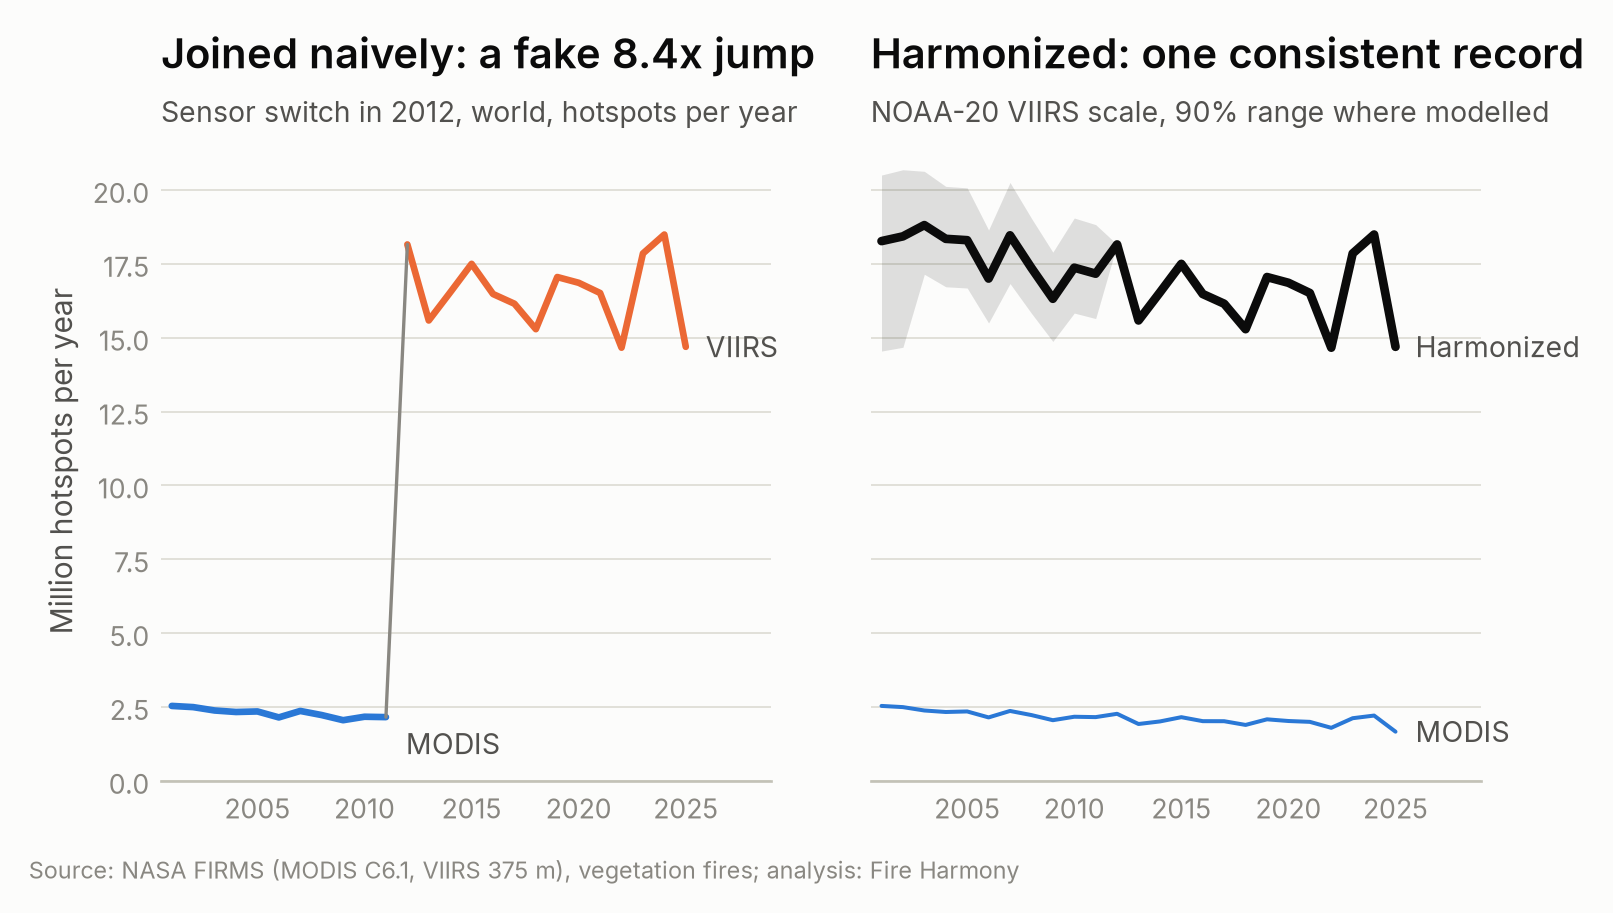

In [10]:
Image(str(FIG / 'fig03_seam_test.png'), width=900)

## 7. Change point tests

The Pettitt test looks for one sudden change in a series of yearly totals (2001 to 2025). PELT looks for changes in the monthly series after removing the usual season.

In [11]:
pett = pd.DataFrame(val['pettitt_annual_2001_2025']).T[['change_year', 'p']]
pett['PELT breaks'] = pd.Series({k: ', '.join(d[:7] for d in v) for k, v in val['pelt_breaks_monthly'].items()})
pett['PELT breaks within 12 months of a seam'] = pd.Series({s: ', '.join(f"{seam[:7]}: {', '.join(d[:7] for d in v[s]) or 'none'}" for seam, v in val['pelt_breaks_within_12_months_of_seam'].items())
                                                    for s in pett.index})
pett

,change_year,p,PELT breaks,PELT breaks within 12 months of a seam
naive_join,2012.0,0.000315,"2006-01, 2011-11, 2012-09, 2021-11, 2023-02, 2...","2002-07: none, 2012-01: 2011-11, 2012-09"
harmonized,2009.0,0.042924,"2008-07, 2021-11, 2023-02, 2024-10","2002-07: none, 2012-01: none"
modis_scale,2013.0,0.001439,"2006-01, 2013-07, 2021-11, 2023-02, 2024-10","2002-07: none, 2012-01: none"


In [12]:
yearly = world[world.yr.between(2001, 2025)].groupby('yr')[['harmonized', 'modis_scale']].sum()
pd.DataFrame({f'{a} to {b}': yearly.loc[a:b].median() / 1e6 for a, b in ((2001, 2008), (2009, 2016), (2017, 2025))}).round(2).rename_axis('median year (million)')

,2001 to 2008,2009 to 2016,2017 to 2025
median year (million),,,
harmonized,18.33,16.85,16.51
modis_scale,2.36,2.11,2.02


## 8. The model against VIIRS, in the years VIIRS flew

From 2012 we have both: what VIIRS saw and what our model predicts from MODIS alone. The final model was trained on 2012 to 2019 (on a third of the regions), so for those years this is a fit, not a test: the held out test is in notebook 05. The years 2020 to 2025 were never used for training, so they are a real test, and they also show what happens as the MODIS orbits drift.

,viirs_observed,model_terra_aqua,model / observed
yr,,,
2012,16.74,16.97,1.014
2013,15.58,15.58,1.000
2014,16.53,16.39,0.991
2015,17.50,17.30,0.989
2016,16.48,16.23,0.985
2017,16.15,16.28,1.008
2018,15.29,15.44,1.010
2019,17.06,17.14,1.005
2020,16.86,15.93,0.945


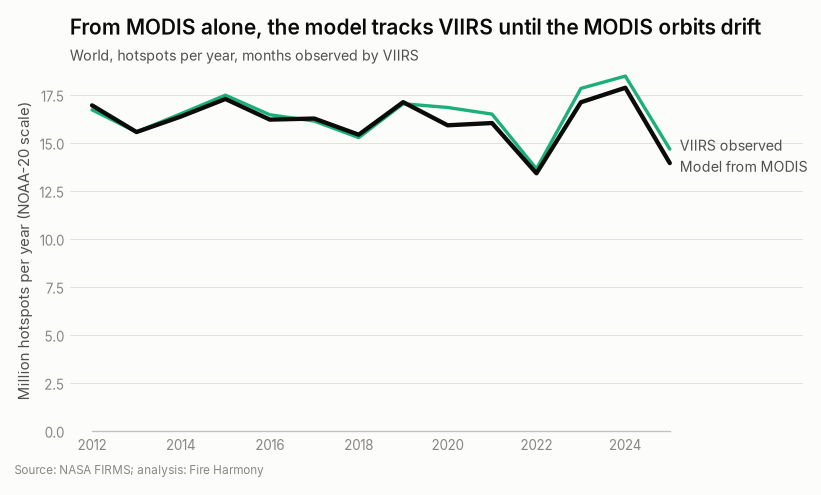

In [13]:
# only months where both exist: January 2012 has no VIIRS value, April 2022 no Terra + Aqua model (Aqua was down)
obs_months = world[world.yr.between(2012, 2025) & world.viirs_observed.notna() & world.model_terra_aqua.notna()]
y = obs_months.groupby('yr')[['viirs_observed', 'model_terra_aqua']].sum()
ratio = (y.model_terra_aqua / y.viirs_observed).rename('model / observed')
fig, ax = plt.subplots(figsize=fh.SIZE['full'])
ax.plot(y.index, y.viirs_observed / 1e6, color=fh.SENSOR['VIIRS_NOAA20'], lw=2)
ax.plot(y.index, y.model_terra_aqua / 1e6, color=fh.INK, lw=2.6)
fh.label_ends(ax, [(y.index[-1], y.viirs_observed.iloc[-1] / 1e6, 'VIIRS observed'),
                   (y.index[-1], y.model_terra_aqua.iloc[-1] / 1e6, 'Model from MODIS')], gap=1.1)
fh.clean(ax); ax.set_xlim(2011.5, 2028); ax.set_ylim(0, None); ax.set_ylabel('Million hotspots per year (NOAA-20 scale)'); fh.year_axis(ax, 2012, 2025, step=2)
fh.title(ax, 'From MODIS alone, the model tracks VIIRS until the MODIS orbits drift', 'World, hotspots per year, months observed by VIIRS')
fh.source(fig, 'Source: NASA FIRMS; analysis: Fire Harmony')
fh.save(fig, FIG / 'fig09_model_vs_viirs')
pd.concat([(y / 1e6).round(2), ratio.round(3)], axis=1)

## 9. Do the worst months stay the worst?

For each continent we rank the months by observed fire and by modelled fire, and compare the rankings: for 2020 to 2025 (never used in training, a real test) and, for reference, for the training years 2012 to 2019.

In [14]:
def rank_test(years):
    cont = V.monthly_series(years=years, by='continent', con=con)
    cont = cont[cont.viirs_observed.notna() & cont.model_terra_aqua.notna()]
    out = []
    for c, g in cont.groupby('continent'):
        if g.viirs_observed.sum() < 1e5:
            continue
        top_obs = set(g.nlargest(10, 'viirs_observed').index); top_mod = set(g.nlargest(10, 'model_terra_aqua').index)
        out.append({'continent': c, 'spearman': g.viirs_observed.corr(g.model_terra_aqua, method='spearman'),
                    'top 10 months shared': len(top_obs & top_mod)})
    return pd.DataFrame(out).set_index('continent')
pd.concat({'2020 to 2025 (test)': rank_test(range(2020, 2026)), '2012 to 2019 (training years)': rank_test(range(2012, 2020))}, axis=1).round(3)

2020 to 2025 (test)                      2012 to 2019 (training years)                     
                         spearman top 10 months shared                      spearman top 10 months shared
continent                                                                                                
Africa                      0.989                    9                         0.997                    9
Asia                        0.981                   10                         0.993                    8
Europe                      0.911                    8                         0.953                    8
North America               0.983                    8                         0.992                    8
Oceania                     0.991                   10                         0.996                    9
South America               0.988                    9                         0.996                    9

> **Key findings**
>
> - Across 2012, MODIS fell by 2.7% and the harmonized record by 1.1%, in step with it. A naive join jumps 7.9 times (8.4 times from 2011 to 2012).
> - Divided by its witness, the harmonized record steps by 0.55% at 2012 (1.65% with three years each side). The naive join steps by about 700%.
> - Before July 2002 the record comes from the Terra only model. In the three years after the seam that model read about 3% below the Terra + Aqua model for the world, and up to 11% apart by continent. We bridge it region by region. Without the bridge the record would step by 3.6% at 2002. With it, the step is 0.85%.
> - Both steps are normal. At dates with no satellite change the same test moves by 5.0% against Terra and 1.2% against MODIS (one standard deviation). The real steps sit 0.07 and 0.37 standard deviations from the placebo mean.
> - Against ESA burned area, which the switch to VIIRS cannot touch, the record steps by 3.2% at 2012, inside the normal spread of 4.2%. From 2003 to 2018 it holds 2.8 to 3.2 hotspots for every km2 burned, with no jump. The naive join jumps by 720%.
> - The MODIS scale view (a toggle in the app) drops by 7.1% in July 2002, because Aqua saw relatively few fires in its first year: 1.86 for each Terra fire, against 1.92 to 2.18 in 2003 to 2020. We state this next to the toggle.
> - Change point tests find a break at the 2012 seam only in the naive join. The harmonized record and MODIS have no break within a year of either seam.
> - Pettitt dates the main change in the harmonized record to 2009 and in MODIS to 2013. Both mark the fall in global fire after the late 2000s: the median year had 18.3 million hotspots in 2001 to 2008 and 16.5 million in 2017 to 2025.
> - The other breaks (late 2021, early 2023, late 2024) appear in MODIS too, so they are fire events, not seams.
> - From MODIS alone, the model matches VIIRS within 1.5% in 2013 to 2019 (training years, so a fit). In the test years 2020 to 2025 it reads 2 to 6% low, as the MODIS orbits drift. The record uses VIIRS itself in those years, so it is not affected.
> - The worst months stay the worst. In the test years the rankings agree at 0.98 or more on every continent but Europe (0.91), and 8 to 10 of the 10 worst months are the same.